# 06 · Validation, decisions and fairness

**Question:** would the champion model be fit for use in a discharge-planning service, and how
should a hospital use it?

Everything here is on **2024/25 discharges the model never saw** (out-of-time validation).
Comparators: the naive baseline, the **LACE index** (a score used in practice), and the oracle
(the true probabilities, available only because the cohort is synthetic).

Validation follows the TRIPOD reporting checklist: discrimination, calibration, internal
validation of optimism, clinical usefulness, and performance in subgroups.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from nhsread import funnel as F
from nhsread import viz
from nhsread.config import COHORT_FILE, MODELS_DIR
from nhsread.evaluation import metrics as M
from nhsread.models import patient as P

viz.set_style()
pd.set_option("display.width", 140)
cohort = pd.read_parquet(COHORT_FILE)
train, test = P.split(cohort)
models = {n: P.SavedModel.load(MODELS_DIR / f"{n}.json") for n in ["champion", "baseline", "lace"]}
y = test["readmit_30d"].to_numpy()
preds = {n: m.predict(test) for n, m in models.items()}
preds["oracle (true risk)"] = test["p_true"].to_numpy()
print(f"validation year {P.TEST_YEAR}: {len(test):,} discharges, observed readmission rate {y.mean():.2%}")

validation year 2024/25: 82,771 discharges, observed readmission rate 14.78%


## 1. Discrimination: does the model rank patients correctly?
AUC is the probability that a randomly chosen readmitted patient scores higher than a randomly
chosen non-readmitted one. Confidence intervals by DeLong's method.

In [2]:
rows = {}
for n, p in preds.items():
    a, lo, hi = M.auc_ci_delong(y, p)
    citl, slope = M.calibration_intercept_slope(y, p)
    rows[n] = {"AUC": a, "AUC 95% CI": f"{lo:.3f}-{hi:.3f}", "Gini": 2 * a - 1, "Brier": M.brier(y, p),
               "log-loss": M.log_loss(y, p), "calibration-in-the-large": citl, "calibration slope": slope}
perf = pd.DataFrame(rows).T
perf.style.format({"AUC": "{:.3f}", "Gini": "{:.3f}", "Brier": "{:.4f}", "log-loss": "{:.4f}",
                   "calibration-in-the-large": "{:+.3f}", "calibration slope": "{:.3f}"})

,AUC,AUC 95% CI,Gini,Brier,log-loss,calibration-in-the-large,calibration slope
champion,0.672,0.667-0.678,0.345,0.1186,0.3932,+0.011,0.978
baseline,0.669,0.664-0.674,0.338,0.1191,0.3945,+0.012,0.978
lace,0.650,0.645-0.655,0.300,0.1206,0.3996,+0.009,0.984
oracle (true risk),0.676,0.671-0.682,0.353,0.1183,0.3919,+0.005,0.992


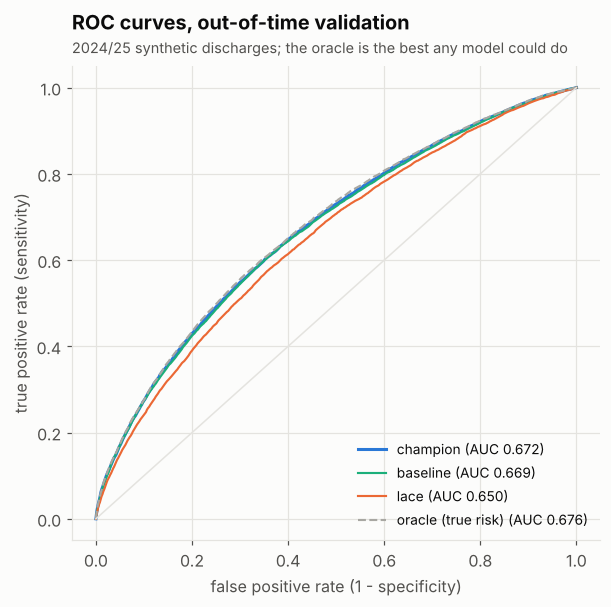

In [3]:
fig, ax = plt.subplots(figsize=(6.2, 5.6))
cols = {"champion": viz.BLUE, "baseline": viz.AQUA, "lace": viz.ORANGE, "oracle (true risk)": viz.GREY}
for n, p in preds.items():
    fpr, tpr = M.roc_curve(y, p)
    k = np.linspace(0, len(fpr) - 1, 400).astype(int)
    ax.plot(fpr[k], tpr[k], color=cols[n], lw=2 if n == "champion" else 1.4,
            ls="--" if n.startswith("oracle") else "-", label=f"{n} (AUC {perf.loc[n, 'AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=viz.GRID, lw=1)
ax.set_xlabel("false positive rate (1 - specificity)")
ax.set_ylabel("true positive rate (sensitivity)")
ax.grid(True, axis="both")
ax.legend(loc="lower right", fontsize=9)
ax.set_title("ROC curves, out-of-time validation")
viz.subtitle(ax, f"{P.TEST_YEAR} synthetic discharges; the oracle is the best any model could do")
viz.save(fig, "06_roc")
fig

The champion closes most of the gap between LACE and the oracle ceiling: it gets as close to the
best achievable ranking as these features allow (0.672 vs 0.676). The remaining gap is mostly the
hospital effect, which no patient-level feature can see.

Note how small the gain over the naive baseline is in AUC (0.003). Better functional form shows up
more clearly in likelihood-based measures (log-loss, AIC) and in calibration at the extremes than
in ranking. AUC alone is a blunt tool for comparing similar models.

## 2. Calibration: are the probabilities right?

* **Calibration-in-the-large** (ideal 0): are average predictions right?
* **Calibration slope** (ideal 1): below 1 means predictions are too extreme (overfitting);
  above 1, too timid.
* **Reliability diagram**: observed vs predicted by decile of risk.

Hosmer-Lemeshow (champion): chi2 = 6.2, p = 0.627


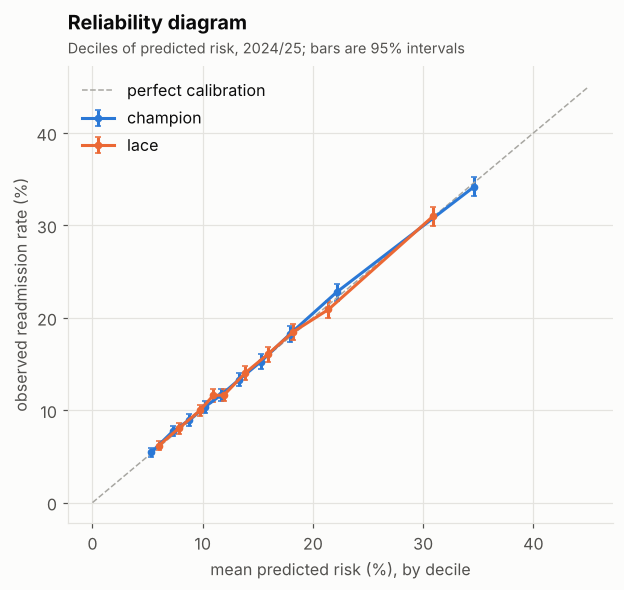

In [4]:
fig, ax = plt.subplots(figsize=(6.4, 5.4))
for n in ["champion", "lace"]:
    t = M.reliability_table(y, preds[n])
    ax.errorbar(100 * t["pred"], 100 * t["obs"], yerr=100 * (t["obs_hi"] - t["obs"]), fmt="o-", color=cols[n],
                capsize=2, ms=4, label=n)
mx = 100 * max(M.reliability_table(y, preds["champion"])["obs"].max(), 0.45)
ax.plot([0, mx], [0, mx], color=viz.GREY, ls="--", lw=1, label="perfect calibration")
ax.set_xlabel("mean predicted risk (%), by decile")
ax.set_ylabel("observed readmission rate (%)")
ax.grid(True, axis="both")
ax.legend(loc="upper left")
ax.set_title("Reliability diagram")
viz.subtitle(ax, "Deciles of predicted risk, 2024/25; bars are 95% intervals")
viz.save(fig, "06_calibration")
hl, hl_p = M.hosmer_lemeshow(y, preds["champion"])
print(f"Hosmer-Lemeshow (champion): chi2 = {hl:.1f}, p = {hl_p:.3f}")
fig

The champion sits on the diagonal across the risk range, with a calibration slope close to 1 on
a year it never saw. The **Hosmer-Lemeshow** test does not reject here, but with very large
samples it often rejects clinically trivial miscalibration, so the reliability diagram and the
calibration slope are the more useful evidence.

## 3. Internal validation: how optimistic is the training performance?

Harrell's bootstrap: refit the whole model on resamples of the training data, measure how much
better each refit does on its own sample than on the original data, and subtract that
**optimism**. This is the standard way to estimate how a model will do on new patients from the
same population, before any external test.

In [5]:
rng = np.random.default_rng(0)
ytr = train["readmit_30d"].to_numpy()
champ_tr = P.fit(train)
app_auc = M.auc(ytr, champ_tr.predict(train))
app_slope = 1.0
opt_auc, opt_slope = [], []
B = 30
for _ in range(B):
    idx = rng.integers(0, len(train), len(train))
    bs = train.iloc[idx].reset_index(drop=True)
    r = P.fit(bs)
    opt_auc.append(M.auc(bs["readmit_30d"], r.predict(bs)) - M.auc(ytr, r.predict(train)))
    opt_slope.append(1 - M.calibration_intercept_slope(ytr, r.predict(train))[1])
pd.DataFrame({
    "apparent (training)": [app_auc, app_slope],
    "mean optimism": [np.mean(opt_auc), np.mean(opt_slope)],
    "optimism-corrected": [app_auc - np.mean(opt_auc), app_slope - np.mean(opt_slope)],
    f"actual on {P.TEST_YEAR}": [perf.loc["champion", "AUC"], perf.loc["champion", "calibration slope"]],
}, index=["AUC", "calibration slope"]).round(4)

,apparent (training),mean optimism,optimism-corrected,actual on 2024/25
AUC,0.6756,0.0001,0.6755,0.6724
calibration slope,1.0000,0.0008,0.9992,0.9781


With 157,000 training patients and 20 coefficients, optimism is tiny (well under 0.01 AUC), and
the optimism-corrected estimate is close to what we actually see on the next year. The small
extra drop on 2024/25 comes from the year changing (case mix and rates drift), which bootstrap
resampling of the training years cannot see: that is why an out-of-time test is needed too. With a few
thousand patients and many candidate variables, this correction becomes large, and the bootstrap
is what tells you so before deployment.

## 4. From a probability to a decision

A risk score is only useful if it changes what happens to patients. Suppose the hospital can
offer a **post-discharge follow-up** (a phone call and a community nurse visit). We need a
threshold: offer it to patients above X% risk.

**Assumptions (all adjustable in the dashboard):**

| Quantity | Assumed value | Note |
|---|---|---|
| Cost of the follow-up per patient | £150 | phone call + one community visit |
| Cost of an emergency readmission | £2,500 | order of magnitude of a short non-elective stay |
| Readmissions prevented among those followed up | 20% | transitional-care trials report roughly 10-30% |

These are illustrative, not NHS reference costs.

In [6]:
C_INT, C_READ, EFF = 150, 2500, 0.20
p_ch = preds["champion"]
grid = np.round(np.arange(0.05, 0.505, 0.05), 2)
dec = pd.DataFrame([M.confusion_at(y, p_ch, t) for t in grid])
dec["cost per discharge (£)"] = [M.expected_cost(y, p_ch, t, C_INT, C_READ, EFF) for t in grid]
dec["readmissions prevented per 1,000"] = [1000 * EFF * ((p_ch >= t) & (y == 1)).sum() / len(y) for t in grid]
dec[["threshold", "flagged_pct", "sensitivity", "ppv", "readmissions prevented per 1,000", "cost per discharge (£)"]].round(3)

,threshold,flagged_pct,sensitivity,ppv,"readmissions prevented per 1,000",cost per discharge (£)
0,0.05,96.716,0.990,0.151,29.261,441.464
1,0.10,66.322,0.827,0.184,24.448,407.906
2,0.15,36.153,0.573,0.234,16.946,381.409
3,0.20,19.016,0.371,0.288,10.956,370.679
4,0.25,10.525,0.239,0.335,7.060,367.681
5,0.30,5.938,0.153,0.380,4.516,367.161
6,0.35,3.455,0.103,0.441,3.047,367.109
7,0.40,2.059,0.069,0.492,2.027,367.564
8,0.45,1.273,0.044,0.515,1.312,368.174
9,0.50,0.754,0.029,0.575,0.867,368.506


In [7]:
t_opt, curve = M.cost_optimal_threshold(y, p_ch, C_INT, C_READ, EFF)
base_cost = C_READ * y.mean()
best = curve["cost_per_discharge"].min()
theory = C_INT / (EFF * C_READ)
print(f"cost-optimal threshold: {t_opt:.0%} (theory: intervene when p x {EFF:.0%} x £{C_READ:,} > £{C_INT}, i.e. p > {theory:.0%})")
print(f"cost per discharge: no programme £{base_cost:,.0f}, model-targeted £{best:,.0f} "
      f"-> saving £{base_cost - best:.2f} per discharge, about £{(base_cost - best) * 6.4e6 / 1e6:,.0f}m a year at England's 6.4m discharges")
print(f"follow up everyone instead: £{M.expected_cost(y, p_ch, 0, C_INT, C_READ, EFF):,.0f} per discharge")

cost-optimal threshold: 31% (theory: intervene when p x 20% x £2,500 > £150, i.e. p > 30%)
cost per discharge: no programme £370, model-targeted £367 -> saving £2.51 per discharge, about £16m a year at England's 6.4m discharges
follow up everyone instead: £446 per discharge


The cost-optimal threshold matches simple decision theory: intervene when expected savings
(risk x effectiveness x readmission cost) exceed the intervention cost.

Be honest about the size of the prize. Under these assumptions, model-targeted follow-up beats
doing nothing by only about £2.50 per discharge, because only about 6% of patients are risky
enough for the follow-up to pay for itself. The big win is against the blanket alternative:
following up everyone costs about £446 per discharge against £367. The result is very sensitive to
the assumed effectiveness, which is the number to pin down before any business case (try it in
the dashboard). Good **calibration** is
what makes this work. A miscalibrated model (for example one trained with balanced class
weights, notebook 05) would put every patient above the threshold.

### Decision-curve analysis
Net benefit (Vickers and Elkin) puts true and false positives on one scale for a range of
thresholds, compared with "follow up everyone" and "follow up no one".

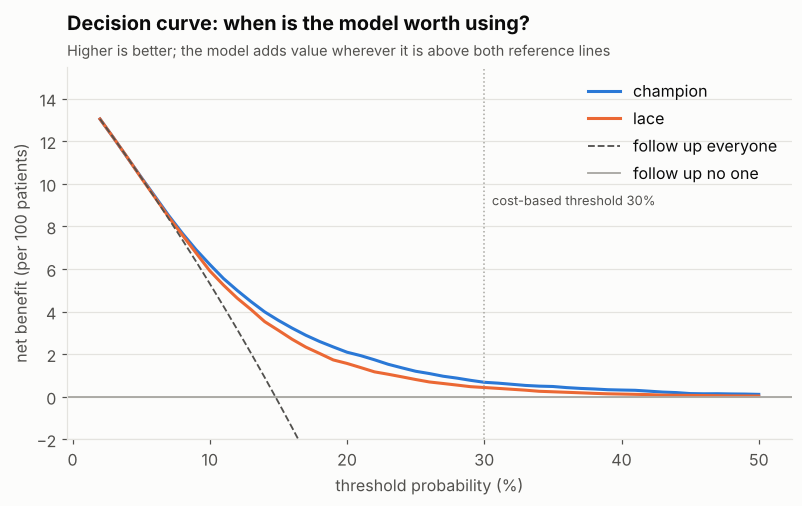

In [8]:
ts = np.linspace(0.02, 0.5, 49)
fig, ax = plt.subplots(figsize=(8.5, 4.4))
for n in ["champion", "lace"]:
    nb = M.net_benefit(y, preds[n], ts)
    ax.plot(nb["threshold"] * 100, nb["model"] * 100, color=cols[n], label=n)
ax.plot(ts * 100, nb["treat_all"] * 100, color=viz.TEXT_2, ls="--", lw=1.2, label="follow up everyone")
ax.axhline(0, color=viz.GREY, lw=1.2, label="follow up no one")
ax.axvline(theory * 100, color=viz.GREY, ls=":", lw=1)
ax.annotate(f"cost-based threshold {theory:.0%}", (theory * 100, 9), xytext=(5, 0), textcoords="offset points", fontsize=8.5,
            color=viz.TEXT_2)
ax.set_ylim(-2, 15.5)
ax.set_xlabel("threshold probability (%)")
ax.set_ylabel("net benefit (per 100 patients)")
ax.legend(loc="upper right")
ax.set_title("Decision curve: when is the model worth using?")
viz.subtitle(ax, "Higher is better; the model adds value wherever it is above both reference lines")
viz.save(fig, "06_decision_curve")
fig

## 5. Fairness: does the model work equally well for everyone?

At the cost-based threshold we compare, by deprivation quintile, age band and sex:
**calibration** (observed / expected, ideal 1), **discrimination** (AUC), and **who gets flagged**
(flag rate, sensitivity, false-positive rate).

In [9]:
fair = pd.concat({
    "deprivation (1 = most)": M.group_report(y, p_ch, test["imd"].astype(int), t_opt),
    "age band": M.group_report(y, p_ch, test["age_band"].astype(str), t_opt),
    "sex": M.group_report(y, p_ch, test["sex"].astype(str), t_opt),
})
fair.droplevel(1).set_index("group", append=True)[["n", "obs_rate", "mean_pred", "o_to_e", "auc", "flagged_pct",
                                                    "sensitivity", "fpr"]].round(3)

n  obs_rate  mean_pred  o_to_e    auc  flagged_pct  sensitivity    fpr
                       group                                                                             
deprivation (1 = most) 1       20127     0.161      0.156   1.035  0.680        6.459        0.171  0.044
                       2       17332     0.150      0.149   1.010  0.675        5.614        0.148  0.040
                       3       16234     0.144      0.146   0.992  0.672        4.829        0.128  0.035
                       4       15130     0.140      0.141   0.988  0.668        4.349        0.113  0.032
                       5       13948     0.138      0.137   1.010  0.658        3.542        0.103  0.025
age band               16-74   51336     0.138      0.137   1.007  0.664        3.775        0.102  0.027
                       75+     20617     0.182      0.179   1.015  0.690       10.705        0.247  0.076
                       <16     10818     0.129      0.128   1.005  0.634        0.592        0.021  0.004
sex                    Female  45613     0.147      0.144   1.017  0.668        4.913        0.129  0.035
                       Male    37158     0.149      0.149   1.000  0.678        5.296        0.147  0.036

* **Calibration holds in every group** (O/E close to 1), so a given score means the same risk
  whoever the patient is. This is the property that matters most for a clinical risk score.
* **Flag rates differ** because underlying risk differs: older patients and those from more
  deprived areas are flagged more often. With a calibrated model and a common threshold, that is
  need-based allocation of follow-up, not bias.
* **AUC is lowest for children** (about 0.63): the clinical features used here (comorbidity,
  prior admissions) say less about a child's risk, so a paediatric service would need its own
  predictors.

### Should deprivation be a predictor?
Including IMD lets the model use real differences in risk; excluding it ("fairness through
unawareness") is often proposed. We can measure the trade-off directly:

In [10]:
no_imd_formula = P.CHAMPION_FORMULA.replace(" + C(imd)", "")
no_imd = P.to_saved(P.fit(train, no_imd_formula), "no_imd", no_imd_formula, len(train))
p_no = no_imd.predict(test)
cmp = pd.DataFrame({
    "with IMD": M.group_report(y, p_ch, test["imd"].astype(int), t_opt).set_index("group")["o_to_e"],
    "without IMD": M.group_report(y, p_no, test["imd"].astype(int), t_opt).set_index("group")["o_to_e"],
})
cmp.index.name = "IMD quintile (O/E)"
print(f"AUC with IMD {M.auc(y, p_ch):.4f}, without {M.auc(y, p_no):.4f}")
cmp.round(3)

AUC with IMD 0.6724, without 0.6722


,with IMD,without IMD
IMD quintile (O/E),,
1,1.035,1.011
2,1.010,0.984
3,0.992,0.991
4,0.988,1.010
5,1.010,1.065


Dropping IMD barely changes the AUC, but it **does** change calibration by group: the least
deprived fifth becomes under-predicted by about 6% (O/E 1.065). In this cohort, once clinical
features are known, the remaining (direct) deprivation effect runs the other way (notebook 05,
section 6), so removing IMD shifts error onto one group. "Fairness through unawareness" does not
guarantee fair predictions; checking calibration within groups does. On real data, if removing
IMD left *deprived* patients under-predicted, it would mean fewer follow-ups for those who need
them most.

## 6. Bringing it back to hospitals: patient-level case-mix adjustment

The patient model gives every discharge an expected risk. Summing those by hospital gives an
expected count that adjusts for far more than age and sex, which is exactly what SHMI-style
indicators do. In the synthetic data we also know each hospital's true effect, so we can check
whether the funnel recovers it.

In [11]:
h = test.assign(p=p_ch).groupby("provider").agg(O=("readmit_30d", "sum"), E=("p", "sum"), n=("p", "size"))
h["SR"] = h["O"] / h["E"]
true_u = (test.assign(lp=np.log(test["p_true"] / (1 - test["p_true"])) - np.log(p_ch / (1 - p_ch)))
          .groupby("provider")["lp"].mean())
h["true effect"] = true_u
od = F.estimate_overdispersion(h["O"], h["E"])
h["band"] = F.overdispersed_band(h["O"], h["E"], od.tau2)
print(f"{len(h)} synthetic hospitals; phi = {od.phi:.2f}, tau = {np.sqrt(od.tau2):.3f}; "
      f"corr(log SR, true hospital effect) = {np.corrcoef(np.log(h['SR']), h['true effect'])[0, 1]:.2f}")
print("bands:", h["band"].value_counts().to_dict())

60 synthetic hospitals; phi = 2.52, tau = 0.044; corr(log SR, true hospital effect) = 0.89
bands: {'W': 54, 'B5': 3, 'A5': 3}


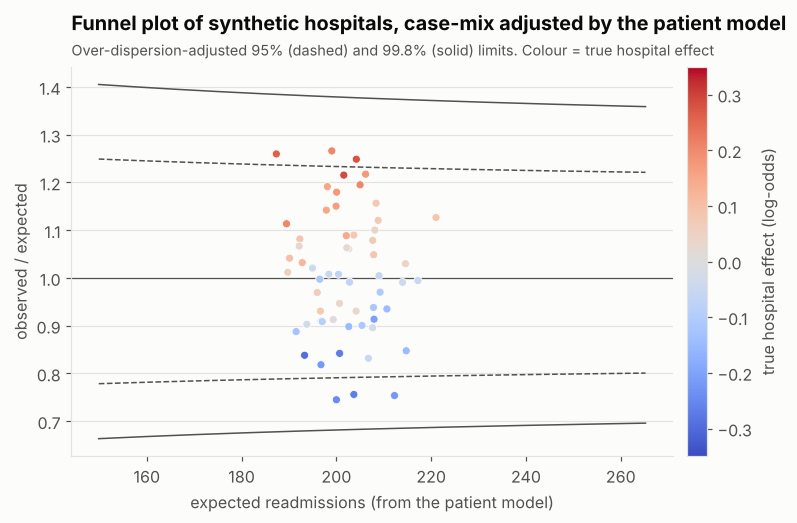

In [12]:
fr = F.funnel_frame(h["O"], h["E"], tau2=od.tau2)
fig, ax = plt.subplots(figsize=(8.5, 4.6))
sc = ax.scatter(h["E"], h["SR"], c=h["true effect"], cmap="coolwarm", vmin=-0.35, vmax=0.35, s=28, zorder=3,
                edgecolor="white", linewidth=0.5)
for z, ls in [("95", "--"), ("998", "-")]:
    ax.plot(fr["expected"], fr[f"od_lo{z}"], color=viz.TEXT_2, lw=1, ls=ls)
    ax.plot(fr["expected"], fr[f"od_hi{z}"], color=viz.TEXT_2, lw=1, ls=ls)
ax.axhline(1, color=viz.TEXT_2, lw=0.8)
cb = fig.colorbar(sc, ax=ax, pad=0.02)
cb.set_label("true hospital effect (log-odds)")
ax.set_xlabel("expected readmissions (from the patient model)")
ax.set_ylabel("observed / expected")
ax.set_title("Funnel plot of synthetic hospitals, case-mix adjusted by the patient model")
viz.subtitle(ax, "Over-dispersion-adjusted 95% (dashed) and 99.8% (solid) limits. Colour = true hospital effect")
viz.save(fig, "06_hospital_funnel")
fig

Adjusting with the patient model, the funnel ranks hospitals in line with their (known) true
effects. This links the two halves of the project: Part 1's benchmarking on real NHS data used
age and sex only; with patient-level records, the same funnel would use a model like this one.

## 7. Record the validation results

In [13]:
summary = {
    "validation_year": P.TEST_YEAR,
    "n_validation": int(len(test)),
    "event_rate": float(y.mean()),
    "auc": {n: float(perf.loc[n, "AUC"]) for n in perf.index},
    "calibration_slope": {n: float(perf.loc[n, "calibration slope"]) for n in perf.index},
    "calibration_in_the_large": {n: float(perf.loc[n, "calibration-in-the-large"]) for n in perf.index},
    "brier": {n: float(perf.loc[n, "Brier"]) for n in perf.index},
    "bootstrap_optimism_auc": float(np.mean(opt_auc)),
    "cost_assumptions": {"intervention": C_INT, "readmission": C_READ, "effectiveness": EFF},
    "cost_optimal_threshold": t_opt,
    "saving_per_discharge": float(base_cost - best),
}
(MODELS_DIR / "validation_summary.json").write_text(json.dumps(summary, indent=2))
pd.Series({k: v for k, v in summary.items() if not isinstance(v, dict)})

validation_year            2024/25
n_validation                 82771
event_rate                0.147817
bootstrap_optimism_auc    0.000079
cost_optimal_threshold       0.315
saving_per_discharge       2.51477
dtype: object

**Takeaways**

* Out of time, the champion reaches AUC about 0.67 against an oracle ceiling of about 0.68, and
  beats LACE (about 0.65). It is well calibrated on a year it never saw.
* Bootstrap optimism is negligible at this sample size, and agrees with the out-of-time result.
* Under stated cost assumptions, the cost-optimal threshold (about 30%) follows from decision
  theory. Targeting is far cheaper than a blanket programme, but only marginally cheaper than none:
  the case rests on the intervention's effectiveness.
* Calibration holds across deprivation, age and sex groups; flag rates differ because need differs.
  Removing deprivation as a predictor does not make the model fairer; it miscalibrates a group.
* The same model provides case-mix adjustment for hospital funnel plots, linking Parts 1 and 2.